In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

# 1. Install/import required libraries
# If TensorFlow is not installed, uncomment and run:
# %pip install tensorflow scikit-learn seaborn matplotlib pandas

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import zipfile

zip_path = "/content/drive/MyDrive/Dataset2.zip"
extract_path = "/content/Dataset2"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)


Extracted to: /content/Dataset2


In [4]:

# 2. Configuration

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_dataset_root(base):
    """Find the folder whose sub-folders contain the class images (ignores __MACOSX etc.)."""
    base = Path(base)
    candidates = [base] + [p for p in base.rglob("*") if p.is_dir()]
    for cand in candidates:
        if "__MACOSX" in cand.parts:
            continue
        subdirs = [d for d in cand.iterdir()
                   if d.is_dir() and not d.name.startswith((".", "__"))]
        if len(subdirs) >= 2 and all(
            any(f.suffix.lower() in IMAGE_EXTENSIONS for f in d.rglob("*") if f.is_file())
            for d in subdirs
        ):
            return cand
    raise FileNotFoundError("Could not find class folders inside " + str(base))

DATASET_DIR = find_dataset_root("/content/Dataset2")

# Optional: rename class folders for display (not needed here, folders are already named Healthy / MLB / MSV)
CLASS_RENAME = {}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 70

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Dataset path:", DATASET_DIR)
print("Exists:", DATASET_DIR.exists())
print("Class folders:", sorted(p.name for p in DATASET_DIR.iterdir() if p.is_dir()))


Dataset path: /content/Dataset2/Dataset2
Exists: True
Class folders: ['Healthy', 'MLB', 'MSV']


In [5]:

# 3. Scan the dataset and create a dataframe

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}\n"
        "Please update DATASET_DIR in the previous cell."
    )

class_dirs = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()])
class_names = [CLASS_RENAME.get(p.name, p.name) for p in class_dirs]

records = []
for class_dir in class_dirs:
    for file_path in class_dir.rglob("*"):
        if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "filepath": str(file_path),
                "label": CLASS_RENAME.get(class_dir.name, class_dir.name)
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No image files were found. Check the dataset path and image extensions.")

print("Classes:", class_names)
print("Total images:", len(df))
display(df.head())


Classes: ['Healthy', 'MLB', 'MSV']
Total images: 18916


,filepath,label
0,/content/Dataset2/Dataset2/Healthy/16218442692...,Healthy
1,/content/Dataset2/Dataset2/Healthy/16215761955...,Healthy
2,/content/Dataset2/Dataset2/Healthy/16214891883...,Healthy
3,/content/Dataset2/Dataset2/Healthy/16215761665...,Healthy
4,/content/Dataset2/Dataset2/Healthy/16216717184...,Healthy


In [6]:
# 3b. Remove corrupted / unreadable images
# Some JPEGs in the dataset are damaged and crash tf.io.decode_image during training.
# We test-decode every file the same way the training pipeline does, and drop the bad ones.

from tqdm.auto import tqdm

bad_files = []
for fp in tqdm(df["filepath"], desc="Checking images"):
    try:
        img = tf.io.decode_image(tf.io.read_file(fp), channels=3, expand_animations=False)
        if img.shape[0] == 0 or img.shape[1] == 0:
            raise ValueError("empty image")
        del img
    except Exception:
        bad_files.append(fp)

print(f"Corrupted images found: {len(bad_files)}")
for fp in bad_files[:20]:
    print("  -", fp)

df = df[~df["filepath"].isin(bad_files)].reset_index(drop=True)
print("Valid images remaining:", len(df))

import gc
gc.collect()


Checking images:   0%|          | 0/18916 [00:00<?, ?it/s]

Corrupted images found: 10
  - /content/Dataset2/Dataset2/MSV/1621332575927.jpg
  - /content/Dataset2/Dataset2/MSV/1621579278251.jpg
  - /content/Dataset2/Dataset2/MSV/1621579993884.jpg
  - /content/Dataset2/Dataset2/MSV/1621498053479.jpg
  - /content/Dataset2/Dataset2/MSV/1621511224601.jpg
  - /content/Dataset2/Dataset2/MSV/Image_3804.jpg
  - /content/Dataset2/Dataset2/MSV/1621413621832.jpg
  - /content/Dataset2/Dataset2/MSV/1621506810503.jpg
  - /content/Dataset2/Dataset2/MSV/1621405978743.jpg
  - /content/Dataset2/Dataset2/MSV/Image_3362.jpg
Valid images remaining: 18906


64

,image_count
label,
Healthy,5326
MLB,5279
MSV,8301


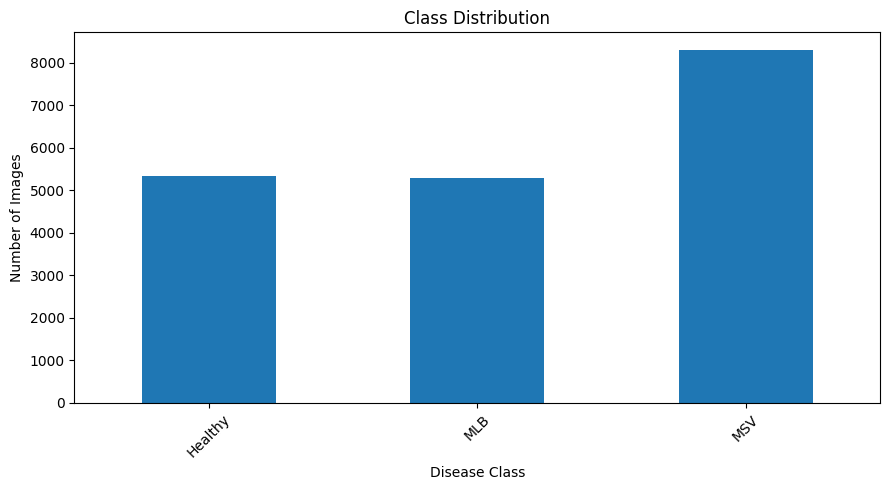

In [7]:

# 4. Check class distribution

class_counts = df["label"].value_counts().sort_index()
display(class_counts.to_frame("image_count"))

plt.figure(figsize=(9, 5))
class_counts.plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


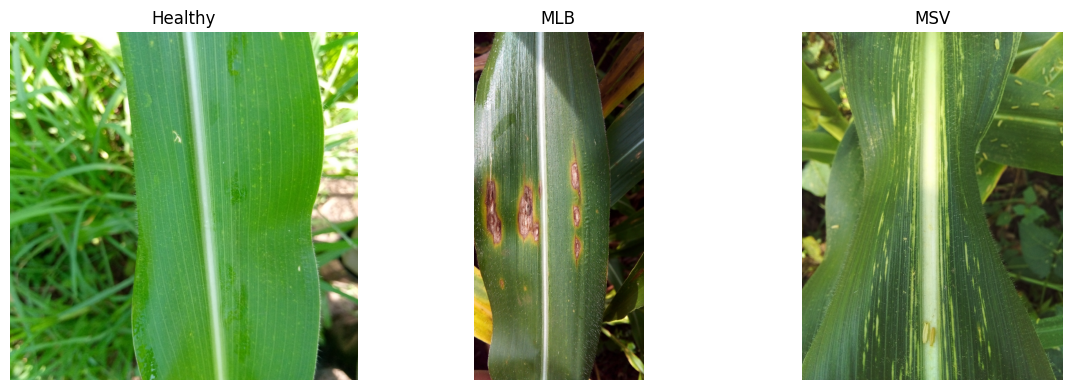

In [8]:

# 5. Display sample images from each class

fig, axes = plt.subplots(1, len(class_names), figsize=(4 * len(class_names), 4))
if len(class_names) == 1:
    axes = [axes]

for ax, class_name in zip(axes, class_names):
    samples = df[df["label"] == class_name]
    row = samples.sample(1, random_state=SEED).iloc[0]

    img = plt.imread(row["filepath"])
    ax.imshow(img)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:

# 6. Encode labels and create train/validation/test splits
# Split: 70% train, 15% validation, 15% test

label_to_index = {name: i for i, name in enumerate(class_names)}
df["label_id"] = df["label"].map(label_to_index)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=SEED
)

print(f"Train: {len(train_df)} images")
print(f"Validation: {len(val_df)} images")
print(f"Test: {len(test_df)} images")

print("\nTrain distribution:")
display(train_df["label"].value_counts().sort_index())


Train: 13234 images
Validation: 2836 images
Test: 2836 images

Train distribution:


,count
label,
Healthy,3728
MLB,3695
MSV,5811


In [10]:

# 7. Create TensorFlow data pipelines
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(class_names)

def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(dataframe, shuffle=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    # IMPORTANT: shuffle BEFORE decoding. At this point each element is just a
    # file path + label (a few bytes), so even a full-size buffer costs almost no RAM.
    # (Shuffling after .map() would keep thousands of decoded 224x224x3 float images in RAM.)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=4)
    ds = ds.batch(BATCH_SIZE).prefetch(2)
    return ds

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Datasets ready.")


Datasets ready.


In [11]:

# 8. Calculate class weights for imbalanced datasets

from sklearn.utils.class_weight import compute_class_weight

classes = np.arange(NUM_CLASSES)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_id"].values
)
class_weights = {int(i): float(w) for i, w in zip(classes, weights)}

print("Class weights:")
for i, weight in class_weights.items():
    print(f"{class_names[i]}: {weight:.4f}")


Class weights:
Healthy: 1.1833
MLB: 1.1939
MSV: 0.7591


In [12]:

# 9. Data augmentation

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.10),
], name="data_augmentation")


In [13]:

# 10. Build a Custom Vision Transformer (ViT) from scratch

PATCH_SIZE = 16
NUM_PATCHES = (IMG_SIZE[0] // PATCH_SIZE) * (IMG_SIZE[1] // PATCH_SIZE)
PROJECTION_DIM = 64
NUM_HEADS = 4
NUM_TRANSFORMER_LAYERS = 4
MLP_DIM = 128
DROPOUT_RATE = 0.10

class PatchEncoder(layers.Layer):
    """Prepends a learnable [CLS] token and adds learnable position embeddings."""

    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.cls_token = self.add_weight(
            shape=(1, 1, projection_dim),
            initializer="random_normal",
            trainable=True,
            name="cls_token",
        )
        self.position_embedding = layers.Embedding(
            input_dim=num_patches + 1, output_dim=projection_dim
        )

    def call(self, patch_embeddings):
        batch_size = tf.shape(patch_embeddings)[0]
        cls_tokens = tf.broadcast_to(
            self.cls_token, [batch_size, 1, self.projection_dim]
        )
        x = tf.concat([cls_tokens, patch_embeddings], axis=1)
        positions = tf.range(start=0, limit=self.num_patches + 1, delta=1)
        x = x + self.position_embedding(positions)
        return x

def transformer_block(x, projection_dim, num_heads, mlp_dim, dropout_rate, name, return_attention=False):
    x1 = layers.LayerNormalization(epsilon=1e-6)(x)
    attn_layer = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=projection_dim // num_heads,
        dropout=dropout_rate,
        name=name + "_mha",
    )
    if return_attention:
        attn_output, attn_scores = attn_layer(x1, x1, return_attention_scores=True)
    else:
        attn_output = attn_layer(x1, x1)
        attn_scores = None
    x2 = layers.Add()([attn_output, x])

    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
    x3 = layers.Dense(mlp_dim, activation="gelu")(x3)
    x3 = layers.Dropout(dropout_rate)(x3)
    x3 = layers.Dense(projection_dim)(x3)
    x3 = layers.Dropout(dropout_rate)(x3)
    x_out = layers.Add()([x3, x2])
    return x_out, attn_scores

inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)

patches = layers.Conv2D(
    filters=PROJECTION_DIM,
    kernel_size=PATCH_SIZE,
    strides=PATCH_SIZE,
    padding="valid",
    name="patch_embedding",
)(x)
patches = layers.Reshape((NUM_PATCHES, PROJECTION_DIM))(patches)

encoded = PatchEncoder(NUM_PATCHES, PROJECTION_DIM)(patches)
encoded = layers.Dropout(DROPOUT_RATE)(encoded)

attn_scores_last = None
for i in range(NUM_TRANSFORMER_LAYERS):
    is_last_block = (i == NUM_TRANSFORMER_LAYERS - 1)
    encoded, attn_scores = transformer_block(
        encoded, PROJECTION_DIM, NUM_HEADS, MLP_DIM, DROPOUT_RATE,
        name=f"block{i}", return_attention=is_last_block
    )
    if is_last_block:
        attn_scores_last = attn_scores

encoded = layers.LayerNormalization(epsilon=1e-6)(encoded)
cls_output = encoded[:, 0, :]
x = layers.Dropout(0.30)(cls_output)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs, name="custom_vit")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# A second model (sharing the same weights/graph) that exposes the last
# Transformer block's attention scores, used later for the attention-map XAI.
attention_model = keras.Model(inputs, attn_scores_last)


Model: "custom_vit"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 14, 14,    │     49,216 │ data_augmentatio… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 64)   │          0 │ patch_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 197, 64)   │     12,672 │ reshape[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 197, 64)   │          0 │ patch_encoder[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 197, 64)   │        128 │ dropout[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_mha          │ (None, 197, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 197, 64)   │          0 │ block0_mha[0][0], │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 197, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 197, 128)  │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 197, 64)   │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 197, 64)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 197, 64)   │          0 │ dropout_3[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_mha          │ (None, 197, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 197, 64)   │          0 │ block1_mha[0][0], │
│                     │                   │            │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 197, 64)   │        128 │ add_2[0][0]     

 Total params: 196,099 (766.01 KB)

 Trainable params: 196,099 (766.01 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

# 11. Training callbacks

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_custom_vit_dataset2.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]


In [15]:

# 12. Train the Custom ViT

import gc
gc.collect()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/70
414/414 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.3444 - loss: 1.2751
Epoch 1: val_accuracy improved from None to 0.31206, saving model to best_custom_vit_dataset2.keras

Epoch 1: finished saving model to best_custom_vit_dataset2.keras
414/414 ━━━━━━━━━━━━━━━━━━━━ 238s 521ms/step - accuracy: 0.3487 - loss: 1.1727 - val_accuracy: 0.3121 - val_loss: 1.1200 - learning_rate: 0.0010
Epoch 2/70
414/414 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.4059 - loss: 1.0846
Epoch 2: val_accuracy improved from 0.31206 to 0.55289, saving model to best_custom_vit_dataset2.keras

Epoch 2: finished saving model to best_custom_vit_dataset2.keras
414/414 ━━━━━━━━━━━━━━━━━━━━ 210s 507ms/step - accuracy: 0.4442 - loss: 1.0560 - val_accuracy: 0.5529 - val_loss: 0.9322 - learning_rate: 0.0010
Epoch 3/70
414/414 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - accuracy: 0.5911 - loss: 0.8761
Epoch 3: val_accuracy improved from 0.55289 to 0.66714, saving model to best_custom_vit_dataset2.keras

Epoch 3

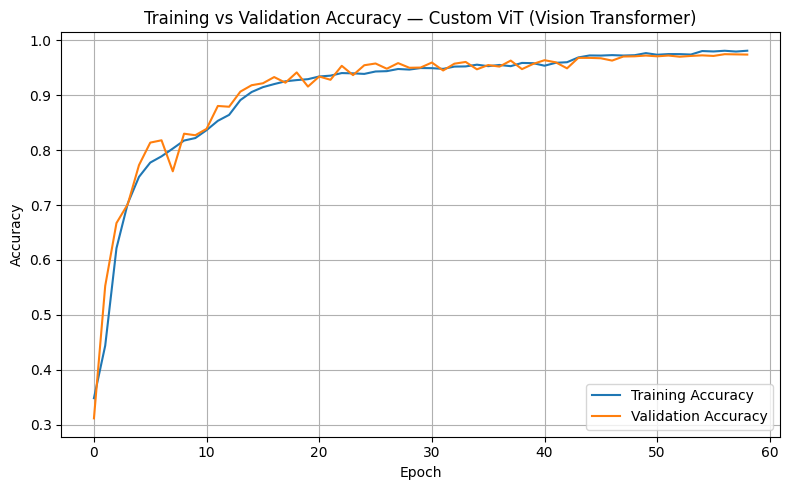

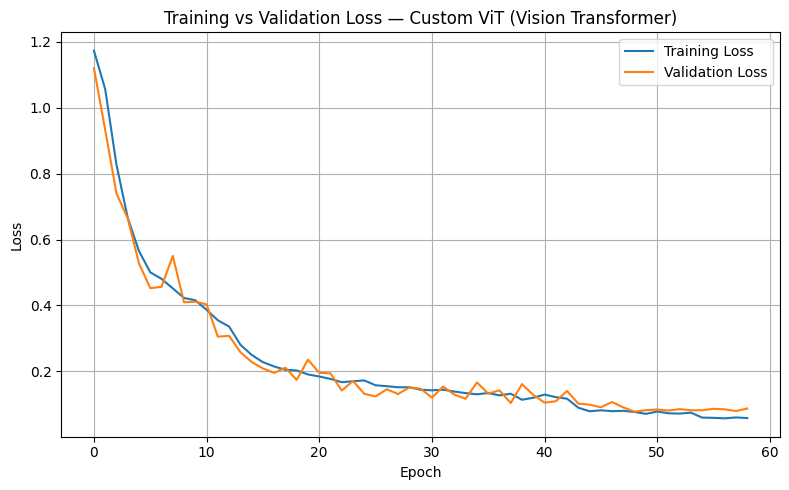

In [16]:

# 13. Plot training and validation accuracy/loss

history_df = pd.DataFrame(history.history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy — Custom ViT (Vision Transformer)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss — Custom ViT (Vision Transformer)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [17]:

# 14. Evaluate on the held-out test set

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")


89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 380ms/step - accuracy: 0.9736 - loss: 0.0882
Test Loss:     0.0882
Test Accuracy: 0.9736 (97.36%)


In [18]:

# 15. Detailed classification report

y_true = test_df["label_id"].values
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0
))


89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 365ms/step
              precision    recall  f1-score   support

     Healthy     0.9782    0.9537    0.9658       799
         MLB     0.9833    0.9659    0.9745       792
         MSV     0.9648    0.9912    0.9778      1245

    accuracy                         0.9736      2836
   macro avg     0.9754    0.9703    0.9727      2836
weighted avg     0.9737    0.9736    0.9735      2836



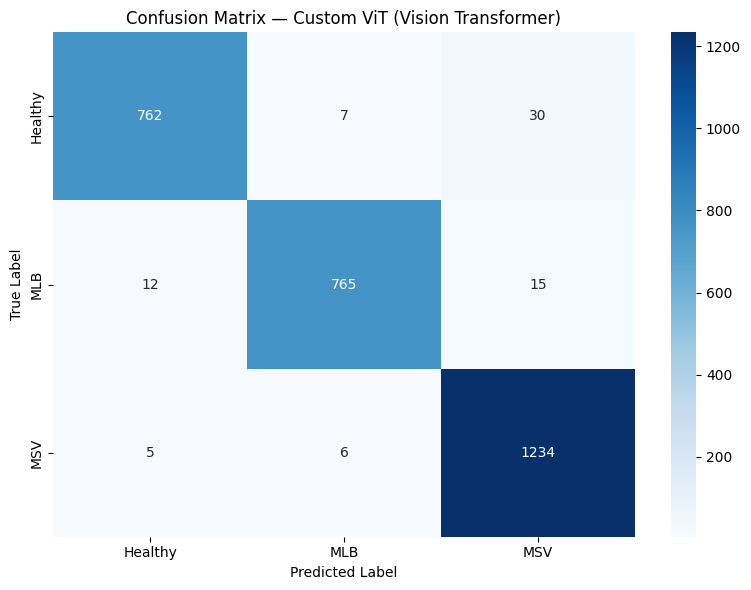

In [19]:

# 16. Confusion matrix

cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix — Custom ViT (Vision Transformer)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


In [20]:

# 17. Precision, recall and F1-score (per class + macro/weighted summary table)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

display(metrics_df)

summary_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1",
               "Weighted Precision", "Weighted Recall", "Weighted F1"],
    "Value": [
        test_accuracy,
        precision.mean(),
        recall.mean(),
        f1.mean(),
        np.average(precision, weights=support),
        np.average(recall, weights=support),
        np.average(f1, weights=support),
    ]
})
display(summary_df)

# Save this table so it can be combined later with the other models'
# notebooks into one master comparison table.
metrics_df.to_csv("metrics_custom_vit_dataset2.csv", index=False)
print("Saved per-class metrics to metrics_custom_vit_dataset2.csv")


,Class,Precision,Recall,F1-Score,Support
0,Healthy,0.978177,0.953692,0.965779,799
1,MLB,0.983290,0.965909,0.974522,792
2,MSV,0.964816,0.991165,0.977813,1245


,Metric,Value
0,Accuracy,0.973554
1,Macro Precision,0.975428
2,Macro Recall,0.970255
3,Macro F1,0.972705
4,Weighted Precision,0.973740
5,Weighted Recall,0.973554
6,Weighted F1,0.973504


Saved per-class metrics to metrics_custom_vit_dataset2.csv


Misclassified test images: 75


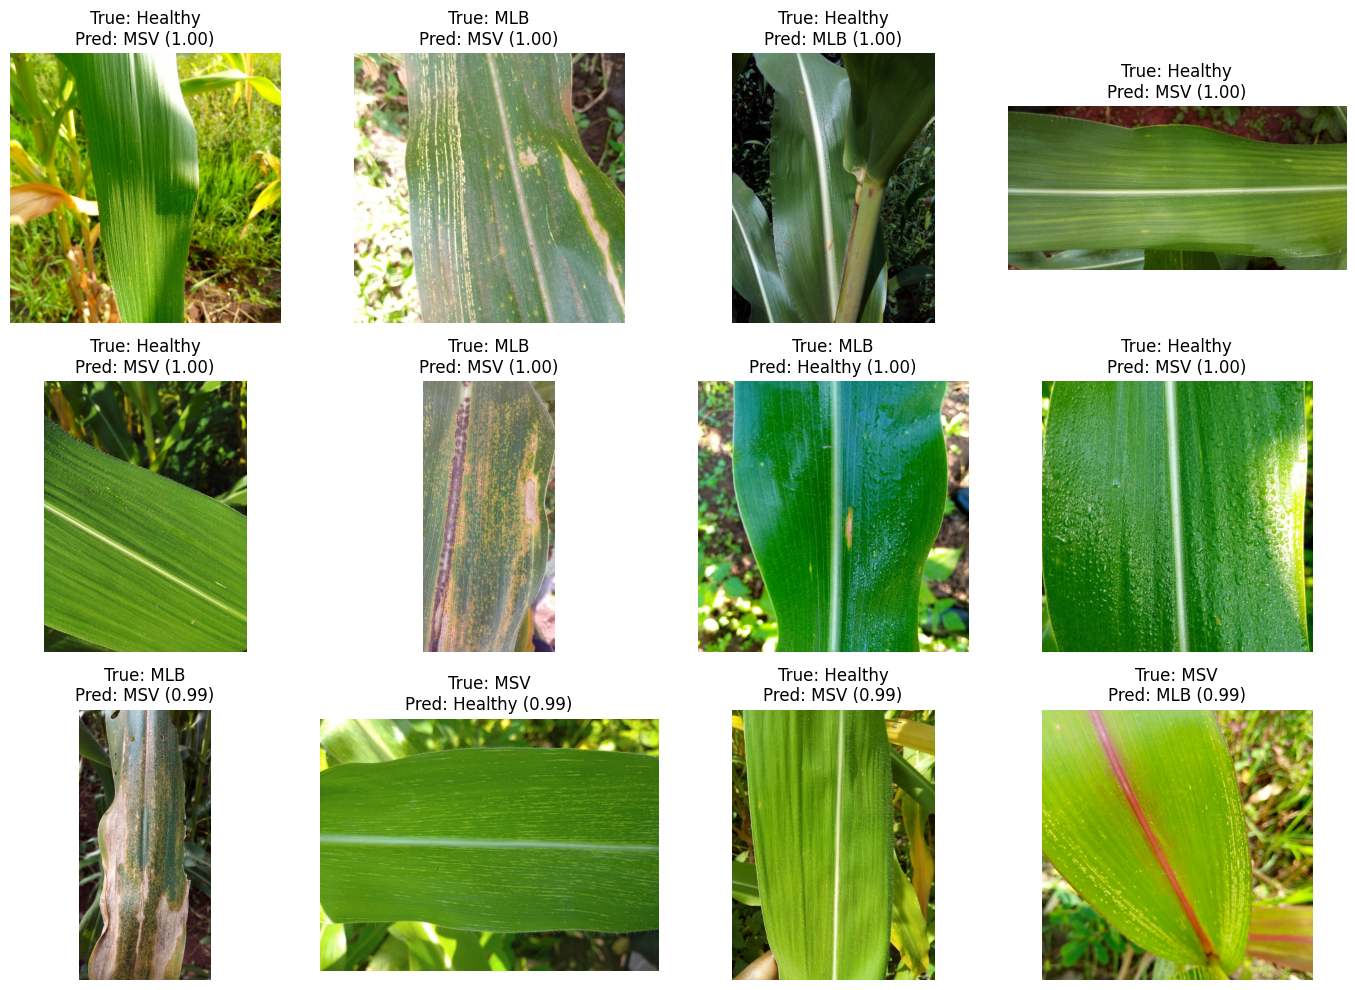

In [21]:

# 18. Show correctly and incorrectly classified test images

results = test_df.copy().reset_index(drop=True)
results["true_id"] = y_true
results["pred_id"] = y_pred
results["true_class"] = [class_names[i] for i in y_true]
results["pred_class"] = [class_names[i] for i in y_pred]
results["confidence"] = np.max(y_prob, axis=1)

wrong = results[results["true_id"] != results["pred_id"]].sort_values(
    "confidence", ascending=False
)

print("Misclassified test images:", len(wrong))

n_show = min(12, len(wrong))

if n_show > 0:
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, wrong.head(n_show).iterrows()):
        img = plt.imread(row["filepath"])
        ax.imshow(img)
        ax.set_title(
            f"True: {row['true_class']}\n"
            f"Pred: {row['pred_class']} ({row['confidence']:.2f})"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified examples to display.")


In [22]:

# 19. Predict a single new image

def preprocess_single_image(image_path):
    image = tf.io.read_file(str(image_path))
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image

def predict_image(image_path, model=model):
    image = preprocess_single_image(image_path)

    probabilities = model.predict(tf.expand_dims(image, axis=0), verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))

    print("Image:", image_path)
    print("Predicted class:", class_names[predicted_id])
    print("Confidence:", f"{probabilities[predicted_id] * 100:.2f}%")

    prediction_df = pd.DataFrame({
        "Class": class_names,
        "Probability": probabilities
    }).sort_values("Probability", ascending=False)

    display(prediction_df)

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"{class_names[predicted_id]} — "
        f"{probabilities[predicted_id] * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

# Example:
# predict_image(r"/content/Dataset2/.../example.jpg")


In [23]:

# 20. Save the final model

MODEL_PATH = "custom_vit_dataset2_final.keras"
model.save(MODEL_PATH)

print(f"Model saved to: {os.path.abspath(MODEL_PATH)}")


Model saved to: /content/custom_vit_dataset2_final.keras


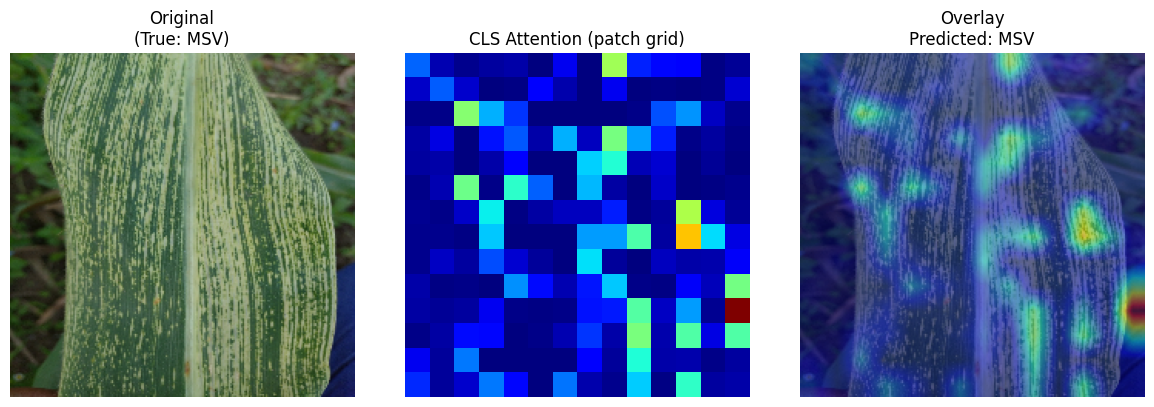

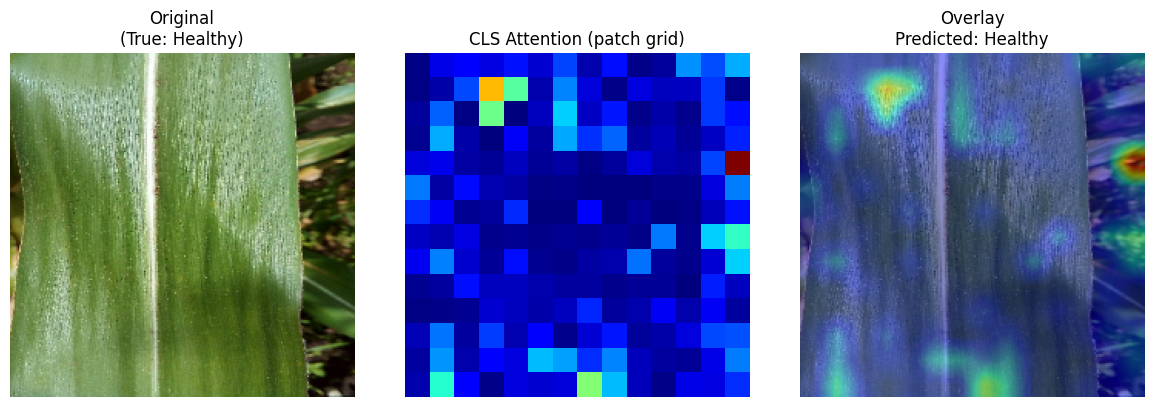

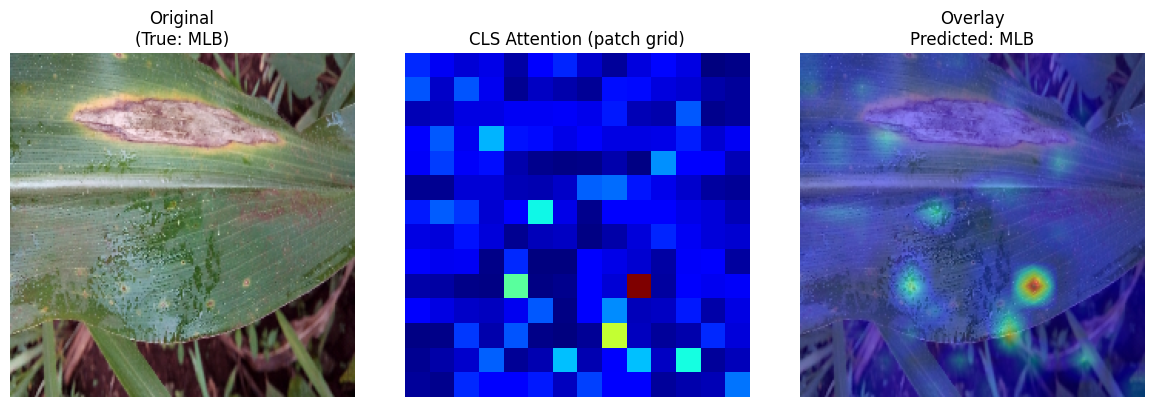

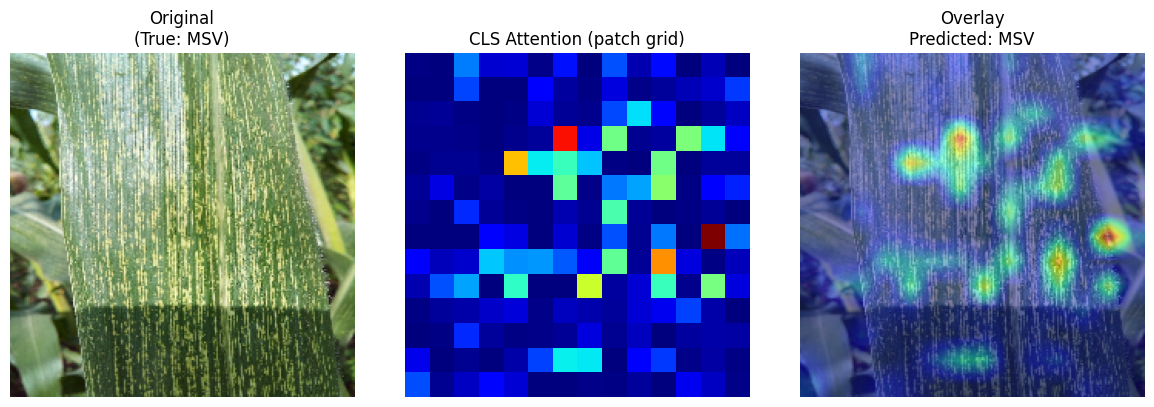

In [24]:

# 21. Explainable AI — CLS-token Attention Map (ViT equivalent of Grad-CAM)

# Vision Transformers don't have convolutional feature maps, so classic Grad-CAM
# does not apply. Instead we visualize how strongly the [CLS] token (which is
# what the final classifier reads) attends to each image patch in the last
# Transformer block. This plays the same explanatory role as Grad-CAM.

def show_attention_map(image_path, true_label=None):
    image = preprocess_single_image(image_path).numpy()
    img_array = np.expand_dims(image, axis=0)

    attn = attention_model.predict(img_array, verbose=0)  # (1, heads, seq, seq)
    attn_cls_to_patches = attn[0, :, 0, 1:]                # (heads, num_patches)
    attn_avg = attn_cls_to_patches.mean(axis=0)            # (num_patches,)

    grid_size = IMG_SIZE[0] // PATCH_SIZE
    attn_map = attn_avg.reshape(grid_size, grid_size)
    attn_map = attn_map / (attn_map.max() + 1e-8)

    probabilities = model.predict(img_array, verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))

    attn_resized = tf.image.resize(
        attn_map[..., np.newaxis], IMG_SIZE
    ).numpy().squeeze()

    original_uint8 = (image * 255).astype("uint8")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original_uint8)
    axes[0].set_title(f"Original\n(True: {true_label})" if true_label else "Original")
    axes[0].axis("off")

    axes[1].imshow(attn_map, cmap="jet")
    axes[1].set_title("CLS Attention (patch grid)")
    axes[1].axis("off")

    axes[2].imshow(original_uint8)
    axes[2].imshow(attn_resized, cmap="jet", alpha=0.45)
    axes[2].set_title(f"Overlay\nPredicted: {class_names[predicted_id]}")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

sample_rows = test_df.sample(min(4, len(test_df)), random_state=SEED)
for _, row in sample_rows.iterrows():
    show_attention_map(row["filepath"], true_label=row["label"])
